In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches


In [2]:
m_values_temp = np.linspace(-5, -2, 100)
Delta_values_temp = np.linspace(0, 0.25, 100)
c_coll_temp = np.loadtxt("ChernNumber_sweep.csv", delimiter=",")

m_values = m_values_temp[1::3]
Delta_values = Delta_values_temp[1::3]
c_coll = c_coll_temp[1::3,1::3]

In [3]:
mu_values_bp = np.linspace(-5, -2, 500)
Delta_values_bp = np.linspace(0, 0.25, 100)

BP_coll = np.loadtxt("BerryPhaseData_sweep_test.csv", delimiter=",")

BP_coll 离散取值: [0.         1.57079633]
c_coll 离散取值: [0 1 2]


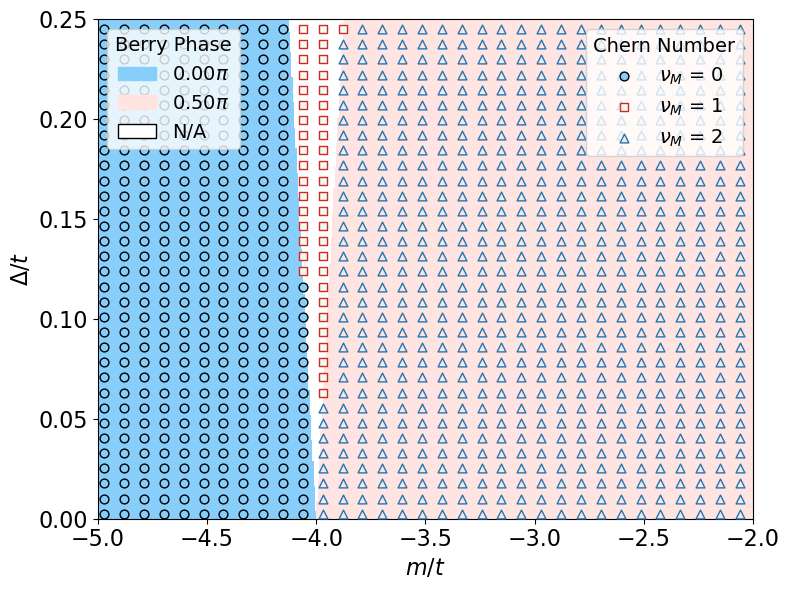

In [5]:
bp_step = np.pi / 4
bp_tolerance = 1e-6
BP_mod = np.mod(BP_coll, np.pi)
BP_discrete = np.mod(np.round(BP_mod / bp_step) * bp_step, np.pi)
valid_bp = (
    np.isclose(BP_mod, 0.0, atol=bp_tolerance, rtol=0.0)
    | np.isclose(BP_mod, np.pi / 2, atol=bp_tolerance, rtol=0.0)
    | np.isclose(BP_mod, np.pi, atol=bp_tolerance, rtol=0.0)
)
BP_discrete = np.ma.masked_where(~valid_bp, BP_discrete)
bp_unique = np.unique(BP_discrete.compressed())
print("BP_coll 离散取值:", bp_unique)

# c_coll 已经是干净的整数
c_unique = np.unique(np.round(c_coll).astype(int))
print("c_coll 离散取值:", c_unique)

# ========== 创建网格坐标 ==========
# BP_coll: (500, 100)，对应 (mu, Delta)
MU_bp, D_bp = np.meshgrid(mu_values_bp, Delta_values_bp, indexing='ij')
# c_coll: (100, 100)，对应 (m, Delta)
MU_c, D_c = np.meshgrid(m_values, Delta_values, indexing='ij')

# ========== 绘图 ==========
fig, ax = plt.subplots(figsize=(8, 6))

# --- BP_coll 背景填色图 ---
# 为每个离散值分配颜色
bp_colors = ['lightskyblue', 'mistyrose', 'honeydew']  # 浅绿过渡色（可根据喜好调整）
if len(bp_unique) > len(bp_colors):
    cmap_temp = plt.cm.get_cmap('Pastel1', len(bp_unique))
    bp_colors = [cmap_temp(i) for i in range(len(bp_unique))]
else:
    bp_colors = bp_colors[:len(bp_unique)]

cmap_bp = ListedColormap(bp_colors)

# 用 BoundaryNorm 把连续值切分到离散颜色
half_step = bp_step / 2
boundaries = [bp_unique[0] - half_step] + [v + half_step for v in bp_unique]
norm_bp = BoundaryNorm(boundaries, cmap_bp.N)

im = ax.pcolormesh(MU_bp, D_bp, BP_discrete, cmap=cmap_bp, norm=norm_bp, shading='auto')

# BP_coll 的 legend（颜色块）
bp_patches = [
    mpatches.Patch(color=bp_colors[i], label=f'{bp_unique[i]/np.pi:.2f}$\pi$')
    for i in range(len(bp_unique))
]
bp_patches.append(mpatches.Patch(facecolor='white', edgecolor='black', label='N/A'))
legend_bp = ax.legend(handles=bp_patches, loc=2, title='Berry Phase', fontsize=14, title_fontsize=14)

# --- c_coll 离散散点图 ---
# marker 与数值对应
marker_map = {0: "o", 1: "s", 2: '^'}
# 散点颜色（深色以便在浅色背景上清晰可见）
c_color_map1 = {0: 'lightskyblue', 1: 'honeydew', 2: 'mistyrose'}
c_color_map2 = {0: 'black', 1: 'tab:red', 2: 'tab:blue'}

for val in c_unique:
    mask = (c_coll == val)
    x_pts = MU_c[mask]
    y_pts = D_c[mask]
    ax.scatter(
        x_pts, y_pts,
        marker=marker_map.get(int(val), 'o'),
        c=c_color_map1.get(int(val), 'black'),
        s=40,
        linewidths=1,
        label=fr'$\nu_M$ = {int(val)}',
        edgecolors=c_color_map2.get(int(val), 'black'),
        zorder=5
    )

# c_coll 的 legend
legend_c = ax.legend(loc=1, title='Chern Number', fontsize=14, title_fontsize=14)
# 将 BP 的 legend 重新加回（scatter legend 会覆盖前一个）
ax.add_artist(legend_bp)

ax.set_xlabel(r'$m / t$', fontsize=16)
ax.set_ylabel(r'$\Delta/t$', fontsize=16)
#ax.set_title('Phase Diagram: Berry Phase & Chern Number', fontsize=14)
ax.set_xlim(mu_values_bp[0], mu_values_bp[-1])
ax.set_ylim(Delta_values_bp[0], Delta_values_bp[-1])
ax.tick_params(axis='both', which='major', labelsize=16)

plt.tight_layout()
plt.savefig('phase_diagram.png', dpi=300)
plt.show()
